# 06 · Fitting Experimental Data

ElecSus runs in reverse: `fit_data()` adjusts model parameters until the
computed spectrum matches your measured one, returning best-fit values,
uncertainties and the full [`lmfit`](https://lmfit.github.io) result. This
notebook fits a real Rb D2 spectrum shipped with ElecSus to recover the cell
temperature, then shows the global optimiser and the buffer-gas fitting rules.

```python
best_params, rms, result = em.fit_data(
    data,            # [x_MHz_array, y_array]
    p_dict,          # initial-guess parameter dict
    p_dict_bools,    # {'T': True, ...}: which parameters vary
    data_type='S0',  # which output the data represent
    fit_algorithm='ML')
```

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from elecsus import elecsus_methods as em

from elecsus.libs.plot_style import apply_style, DURHAM_CYCLE
from elecsus.libs.plot_style import d_purple, d_blue, d_red, d_yellow, d_grey

apply_style()
import warnings
# calculate()/fit_data() work with complex arrays; imaginary parts of the
# real-valued outputs are ~0. Silence the cast-to-real warning when plotting.
warnings.filterwarnings('ignore', message='Casting complex values')
det = np.linspace(-6_000, 6_000, 500)  # MHz

## A real measured spectrum

Real fits start from a CSV. ElecSus ships one: a Doppler-broadened Rb D2
absorption spectrum recorded in zero magnetic field through a 75 mm cell at a
nominal 40 °C, from the
[scope2elecsus](https://github.com/durham-qlm/scope2elecsus) tutorial dataset
(Pizzey *et al.*, New J. Phys. **24**, 125001 (2022)). The fit should recover
the temperature.

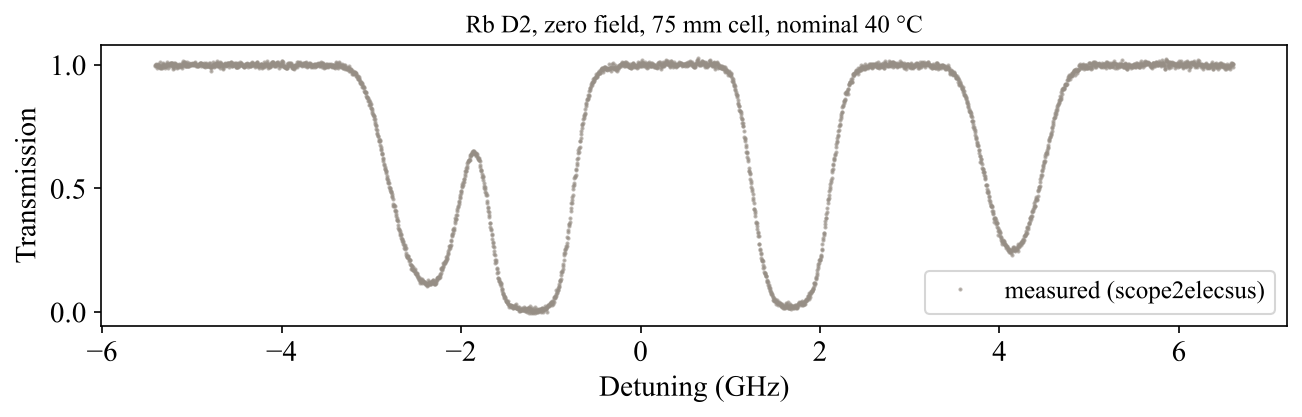

In [2]:
# Load the bundled measurement (Rb D2, zero field, 75 mm cell, nominal 40 C).
from importlib.resources import files

with (files('elecsus') / 'sample_data' / 'rb_d2_doppler_40C.csv').open() as f:
    arr = np.genfromtxt(f, delimiter=',', skip_header=1)
det, signal = arr[:, 0], arr[:, 1]   # detuning (MHz), normalised transmission
data = [det, signal]                 # fit_data format

fig, ax = plt.subplots(figsize=(9, 3))
ax.plot(det/1e3, signal, '.', ms=2, color=d_grey, alpha=0.6, label='measured (scope2elecsus)')
ax.set(xlabel='Detuning (GHz)', ylabel='Transmission',
       title='Rb D2, zero field, 75 mm cell, nominal 40 °C')
ax.legend()
plt.tight_layout()

## Marquardt–Levenberg fit

`fit_algorithm='ML'` is a fast local least-squares fit. Give a reasonable
initial guess and mark which parameters vary; everything else is held fixed.


Perfoming Marquardt-Levenberg fitting routine.


ML Fit completed
recovered  T = 40.10 +/- 0.01 °C   (nominal 40)
RMS residual = 0.86 %


[Text(0.5, 0, 'Detuning (GHz)'), Text(0, 0.5, 'Resid. (%)')]

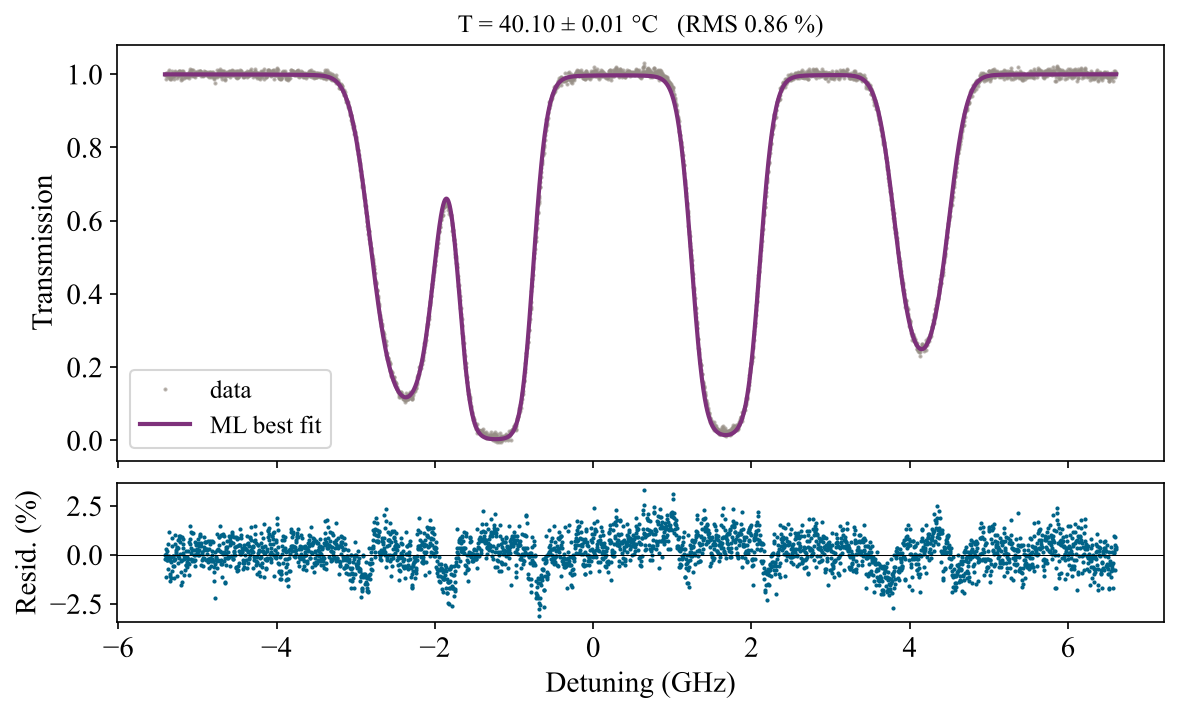

In [3]:
guess = {'Elem':'Rb', 'Dline':'D2', 'T':60., 'lcell':75e-3, 'Bfield':0.}
vary  = {'T': True}   # zero-field data: recover the temperature

best, rms, result = em.fit_data(data, guess, vary, data_type='S0', fit_algorithm='ML')

S0_fit = result.best_fit   # the fitted model at the data's detunings
tE = result.params['T'].stderr
print(f"recovered  T = {best['T']:.2f} +/- {tE:.2f} °C   (nominal 40)")
print(f"RMS residual = {rms*100:.2f} %")

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 5), sharex=True,
                               gridspec_kw={'height_ratios':[3, 1], 'hspace':0.08})
ax1.plot(det/1e3, signal, '.', ms=2, color=d_grey, alpha=0.6, label='data')
ax1.plot(det/1e3, S0_fit.real, color=d_purple, lw=2, label='ML best fit')
ax1.set_ylabel('Transmission'); ax1.legend()
ax1.set_title(f"T = {best['T']:.2f} ± {tE:.2f} °C   (RMS {rms*100:.2f} %)")
ax2.plot(det/1e3, 100*(signal - S0_fit.real), '.', ms=2, color=d_blue)
ax2.axhline(0, color='k', lw=0.5)
ax2.set(xlabel='Detuning (GHz)', ylabel='Resid. (%)')

## Global fit: differential evolution

A local fit can stick in the wrong minimum if the initial guess is poor.
`fit_algorithm='differential_evolution'` searches globally, then polishes with
ML for error bars. **It requires finite bounds on every varying parameter**,
passed as `p_dict_bounds`.

In [4]:
poor_guess = {'Elem':'Rb', 'Dline':'D2', 'T':85., 'lcell':75e-3, 'Bfield':0.}
bounds = {'T': [30., 100.]}

best_de, rms_de, _ = em.fit_data(
    data, poor_guess, {'T':True},
    p_dict_bounds=bounds, data_type='S0',
    fit_algorithm='differential_evolution')

print(f"DE from a poor guess:  T = {best_de['T']:.2f} °C  (nominal 40),  RMS = {rms_de*100:.2f} %")


Perfoming Differential Evolution fitting routine.


DE fitting finished - rounding off with ML fit with optimised parameters...


DE from a poor guess:  T = 40.10 °C  (nominal 40),  RMS = 0.86 %


## Fitting buffer-gas cells

Pass `BufferGas` / `BufferPressure` / `BufferTemp_fill` in the parameter dict.
The model's broadening then replaces `GammaBuf`, and its pressure shift is
added to `shift`, both evaluated at the temperature of the gas in the beam (`T`, or `DoppTemp` with `Constrain=False`). In the vary dict:

- `BufferPressure` may vary: the fit finds the amount of gas in the cell;
- `shift` may vary, as a frequency offset on top of the pressure shift;
- `GammaBuf` may not, as the model replaces it, and nor may `BufferTemp_fill`:
  the model depends on `BufferPressure / BufferTemp_fill` only, so the two are
  degenerate. Either raises `ValueError`.

In [5]:
# synthetic K D1 / Ne buffer-gas data
rng = np.random.default_rng(0)
p_bg_true = {'Elem':'K', 'Dline':'D1', 'T':90., 'lcell':75e-3, 'Bfield':0,
             'BufferGas':'Ne', 'BufferPressure':60., 'BufferTemp_fill':293.15}
det_bg = np.linspace(-4_000, 4_000, 400)
[y_bg] = em.calculate(det_bg, [1, 0, 0], p_bg_true, outputs=['S0'])
y_bg = y_bg.real + rng.normal(0, 0.004, y_bg.shape)
data_bg = [det_bg, y_bg]

# the guard: varying GammaBuf while BufferGas is active is rejected
try:
    em.fit_data(data_bg, p_bg_true, {'T':True, 'GammaBuf':True}, data_type='S0')
except ValueError as e:
    print('Guard raised ValueError as expected:')
    print('  ', e)

# fit the temperature; the model supplies the broadening and shift
p_bg_guess = {**p_bg_true, 'T':80.}
best_bg, rms_bg, _ = em.fit_data(data_bg, p_bg_guess, {'T':True},
                                 data_type='S0', fit_algorithm='ML')
print(f"\nBuffer-gas fit:  T = {best_bg['T']:.2f} °C  (true 90),  RMS = {rms_bg*100:.2f} %")

# ... or the temperature and the amount of gas together
p_bg_guess = {**p_bg_true, 'T':80., 'BufferPressure':40.}
best_bg, rms_bg, res_bg = em.fit_data(data_bg, p_bg_guess, {'T':True, 'BufferPressure':True},
                                      data_type='S0', fit_algorithm='ML')
P_err = res_bg.params['BufferPressure'].stderr
print(f"\nBuffer-gas fit:  T = {best_bg['T']:.2f} °C,  "
      f"P = {best_bg['BufferPressure']:.1f} ± {P_err:.1f} Torr  (true 90 °C, 60 Torr)")

Guard raised ValueError as expected:
   Cannot vary 'GammaBuf' while the buffer-gas model is on (BufferGas='Ne', BufferPressure=60.0): its broadening replaces GammaBuf. Vary 'BufferPressure' to fit the broadening, or leave out 'BufferGas' to fit GammaBuf instead.

Perfoming Marquardt-Levenberg fitting routine.


ML Fit completed

Buffer-gas fit:  T = 90.01 °C  (true 90),  RMS = 0.40 %

Perfoming Marquardt-Levenberg fitting routine.


ML Fit completed

Buffer-gas fit:  T = 90.03 °C,  P = 59.9 ± 0.3 Torr  (true 90 °C, 60 Torr)
